<a href="https://colab.research.google.com/github/maharshipatel28/CFD_23BME078/blob/main/wave_propagation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

EXPERIMENT 3: SMALL-WAVE PROPAGATION

PHYSICAL AND NUMERICAL PARAMETERS
Domain length, L           = 10.0000 m
Water depth, H             = 1.0000 m
Gravitational acceleration = 9.8100 m/s^2
Number of cells, nx        = 200
Grid spacing, dx           = 0.05000000 m
Wave speed, c              = 3.13209195 m/s
Final simulation time      = 0.8000 s
Number of time steps       = 63
Time step, dt              = 0.01269841 s
Actual CFL number          = 0.79545192

INTEGRATED SURFACE DISPLACEMENT
Initial value              = 0.070898154036 m^2
Explicit method            = 0.070898154036 m^2
Implicit method            = 0.070898154036 m^2

RELATIVE CONSERVATION ERRORS
Explicit method            = 0.000000e+00
Implicit method            = 6.655248e-15

L2 ERRORS AGAINST ANALYTICAL SOLUTION
Explicit method            = 0.0058150582
Implicit method            = 0.0236306598

ACCURACY COMPARISON
Explicit method has the smaller L2 error.


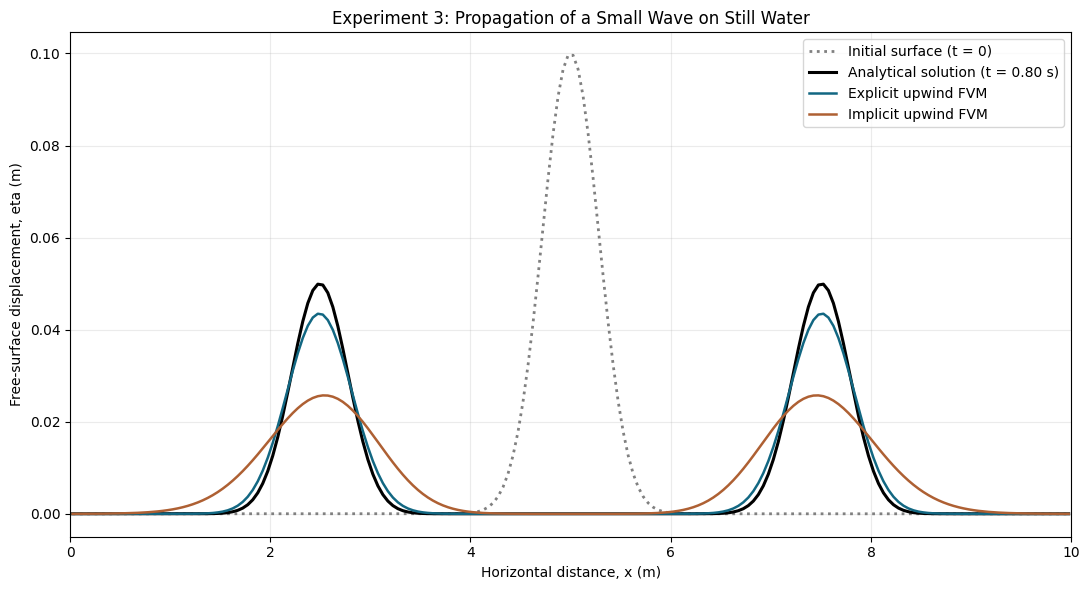


Graph saved as: experiment_3_wave_output.png


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse import lil_matrix
from scipy.sparse.linalg import factorized

# ============================================================
# EXPERIMENT 3: PROPAGATION OF A SMALL WAVE ON STILL WATER
# Comparison of Explicit and Implicit Upwind FVM Schemes
# ============================================================

# 1. PHYSICAL PARAMETERS
L = 10.0              # Domain length (m)
H = 1.0               # Still-water depth (m)
g = 9.81              # Gravitational acceleration (m/s^2)

# 2. NUMERICAL PARAMETERS
nx = 200              # Number of spatial cells
CFL_target = 0.8      # Target CFL number
t_end = 0.80          # Final simulation time (s)

# 3. INITIAL WAVE PARAMETERS
A0 = 0.10             # Initial wave amplitude (m)
width = 0.40          # Gaussian wave-width parameter (m)

# ============================================================
# STEP 1: VALIDATE INPUT PARAMETERS
# ============================================================

if L <= 0 or H <= 0 or g <= 0:
    raise ValueError("L, H, and g must be positive.")

if nx < 2 or int(nx) != nx:
    raise ValueError("nx must be an integer greater than or equal to 2.")

if t_end <= 0 or width <= 0:
    raise ValueError("t_end and width must be positive.")

if A0 <= 0:
    raise ValueError("A0 must be positive.")

if not 0 < CFL_target <= 1:
    raise ValueError("For this explicit scheme, use 0 < CFL_target <= 1.")

nx = int(nx)

# ============================================================
# STEP 2: CALCULATE GRID SIZE, WAVE SPEED, AND TIME STEP
# ============================================================

dx = L / nx
x = (np.arange(nx) + 0.5) * dx

# Linear shallow-water wave speed
c = np.sqrt(g * H)

# Choose the number of time steps to satisfy the target CFL
nsteps = max(1, int(np.ceil(t_end * c / (CFL_target * dx))))

# Adjust dt so that the final time is exactly t_end
dt = t_end / nsteps

# Actual CFL number
lam = c * dt / dx

# ============================================================
# STEP 3: DEFINE A PERIODIC GAUSSIAN PROFILE
# ============================================================

def periodic_gaussian(x, center, amplitude, sigma, domain_length):
    """
    Periodic Gaussian profile, approximated by summing
    neighbouring periodic images.
    """
    result = np.zeros_like(x, dtype=float)

    # Include neighbouring periodic images
    for k in range(-3, 4):
        shifted_x = x - center + k * domain_length
        result += amplitude * np.exp(-(shifted_x / sigma) ** 2)

    return result


# Initial wave centred in the domain
center = L / 2

initial = periodic_gaussian(
    x, center, A0, width, L
)

# ============================================================
# STEP 4: INITIALIZE EXPLICIT AND IMPLICIT SOLUTIONS
# ============================================================

# Right-travelling wave component
r_exp = initial.copy()
r_imp = initial.copy()

# Left-travelling wave component
l_exp = initial.copy()
l_imp = initial.copy()

# ============================================================
# STEP 5: CONSTRUCT IMPLICIT SYSTEM MATRICES
# ============================================================

# Right-travelling wave:
# (1 + lam)*r[i] - lam*r[i-1] = r_old[i]

M_r = lil_matrix((nx, nx), dtype=float)

# Left-travelling wave:
# (1 + lam)*l[i] - lam*l[i+1] = l_old[i]

M_l = lil_matrix((nx, nx), dtype=float)

for i in range(nx):
    # Right-travelling component
    M_r[i, i] = 1.0 + lam
    M_r[i, (i - 1) % nx] = -lam

    # Left-travelling component
    M_l[i, i] = 1.0 + lam
    M_l[i, (i + 1) % nx] = -lam

# Factorize matrices once to reuse at every time step
solve_r = factorized(M_r.tocsc())
solve_l = factorized(M_l.tocsc())

# ============================================================
# STEP 6: TIME INTEGRATION
# ============================================================

for step in range(nsteps):

    # --------------------------------------------------------
    # Explicit upwind method
    # --------------------------------------------------------

    r_exp = r_exp - lam * (r_exp - np.roll(r_exp, 1))

    l_exp = l_exp - lam * (l_exp - np.roll(l_exp, -1))

    # --------------------------------------------------------
    # Implicit upwind method
    # --------------------------------------------------------

    r_imp = solve_r(r_imp)
    l_imp = solve_l(l_imp)

# ============================================================
# STEP 7: CALCULATE FREE-SURFACE DISPLACEMENT
# ============================================================

# The total surface displacement is the average
# of the right- and left-travelling wave components.

eta_exp = 0.5 * (r_exp + l_exp)
eta_imp = 0.5 * (r_imp + l_imp)

# ============================================================
# STEP 8: CALCULATE THE ANALYTICAL SOLUTION
# ============================================================

# Right-travelling Gaussian moves in the +x direction.
# Left-travelling Gaussian moves in the -x direction.

eta_exact = 0.5 * (
    periodic_gaussian(
        x, center + c * t_end, A0, width, L
    )
    +
    periodic_gaussian(
        x, center - c * t_end, A0, width, L
    )
)

# ============================================================
# STEP 9: VOLUME CONSERVATION
# ============================================================

# Integrated surface displacement (m^2 per unit width)
vol_0 = dx * np.sum(initial)
vol_exp = dx * np.sum(eta_exp)
vol_imp = dx * np.sum(eta_imp)

# Relative conservation errors
err_vol_exp = abs(vol_exp - vol_0) / abs(vol_0)
err_vol_imp = abs(vol_imp - vol_0) / abs(vol_0)

# ============================================================
# STEP 10: CALCULATE L2 ERRORS
# ============================================================

l2_exp = np.sqrt(dx * np.sum((eta_exp - eta_exact) ** 2))
l2_imp = np.sqrt(dx * np.sum((eta_imp - eta_exact) ** 2))

# ============================================================
# STEP 11: PRINT NUMERICAL RESULTS
# ============================================================

print("=" * 65)
print("EXPERIMENT 3: SMALL-WAVE PROPAGATION")
print("=" * 65)

print("\nPHYSICAL AND NUMERICAL PARAMETERS")
print(f"Domain length, L           = {L:.4f} m")
print(f"Water depth, H             = {H:.4f} m")
print(f"Gravitational acceleration = {g:.4f} m/s^2")
print(f"Number of cells, nx        = {nx}")
print(f"Grid spacing, dx           = {dx:.8f} m")
print(f"Wave speed, c              = {c:.8f} m/s")
print(f"Final simulation time      = {t_end:.4f} s")
print(f"Number of time steps       = {nsteps}")
print(f"Time step, dt              = {dt:.8f} s")
print(f"Actual CFL number          = {lam:.8f}")

print("\nINTEGRATED SURFACE DISPLACEMENT")
print(f"Initial value              = {vol_0:.12f} m^2")
print(f"Explicit method            = {vol_exp:.12f} m^2")
print(f"Implicit method            = {vol_imp:.12f} m^2")

print("\nRELATIVE CONSERVATION ERRORS")
print(f"Explicit method            = {err_vol_exp:.6e}")
print(f"Implicit method            = {err_vol_imp:.6e}")

print("\nL2 ERRORS AGAINST ANALYTICAL SOLUTION")
print(f"Explicit method            = {l2_exp:.10f}")
print(f"Implicit method            = {l2_imp:.10f}")

print("\nACCURACY COMPARISON")
if l2_exp < l2_imp:
    print("Explicit method has the smaller L2 error.")
elif l2_imp < l2_exp:
    print("Implicit method has the smaller L2 error.")
else:
    print("Both methods have equal L2 errors.")

print("=" * 65)

# ============================================================
# STEP 12: PLOT WAVE PROPAGATION
# ============================================================

plt.figure(figsize=(11, 6))

plt.plot(
    x, initial,
    linestyle=":",
    color="gray",
    linewidth=2,
    label="Initial surface (t = 0)"
)

plt.plot(
    x, eta_exact,
    color="black",
    linewidth=2.2,
    label=f"Analytical solution (t = {t_end:.2f} s)"
)

plt.plot(
    x, eta_exp,
    color="#126782",
    linewidth=1.8,
    label="Explicit upwind FVM"
)

plt.plot(
    x, eta_imp,
    color="#ae6033",
    linewidth=1.8,
    label="Implicit upwind FVM"
)

plt.xlabel("Horizontal distance, x (m)")
plt.ylabel("Free-surface displacement, eta (m)")

plt.title(
    "Experiment 3: Propagation of a Small Wave on Still Water"
)

plt.xlim(0, L)
plt.grid(True, alpha=0.25)
plt.legend()
plt.tight_layout()

# Save the graph
plt.savefig(
    "experiment_3_wave_output.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nGraph saved as: experiment_3_wave_output.png")